In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Load the existing training and test datasets
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

# Select the target variable
y_train = train["pf_pEC50"]
y_test = test["pf_pEC50"]

print("Training compounds:", len(y_train))
print("Test compounds:", len(y_test))


Training compounds: 1349
Test compounds: 338


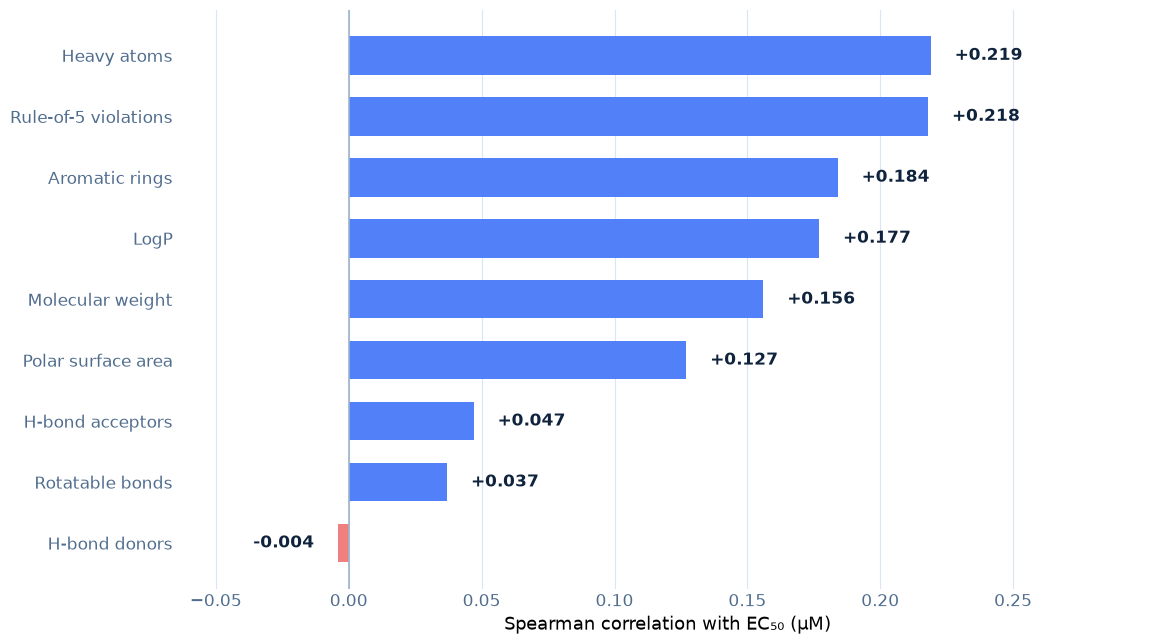

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# COLOURS - change these using HEX codes
bar_colour = "#5180F9"       # Purple (positive correlations)
negative_colour = "#F08080"  # Coral (negative correlations)

# Data from original graph
properties = [
    "H-bond donors",
    "Rotatable bonds",
    "H-bond acceptors",
    "Polar surface area",
    "Molecular weight",
    "LogP",
    "Aromatic rings",
    "Rule-of-5 violations",
    "Heavy atoms"
]

correlations = [
    -0.004, 0.037, 0.047, 0.127, 0.156,
    0.177, 0.184, 0.218, 0.219
]

# Create graph
fig, ax = plt.subplots(figsize=(11.66, 6.54))

colours = [
    bar_colour if value >= 0 else negative_colour
    for value in correlations
]

bars = ax.barh(properties, correlations, color=colours, height=0.63)

# Add correlation values beside bars
for bar, value in zip(bars, correlations):
    ax.text(
        value + (0.009 if value >= 0 else -0.009),
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=12,
        fontweight="bold",
        color="#10233D"
    )

# Formatting
ax.set_xlim(-0.06, 0.30)
ax.set_xticks(np.arange(-0.05, 0.26, 0.05))
ax.set_xlabel("Spearman correlation with EC₅₀ (µM)", fontsize=13)

ax.xaxis.grid(True, color="#D9E5F2")
ax.set_axisbelow(True)
ax.axvline(0, color="#9CB3CC", linewidth=1.2)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="both", length=0, labelsize=12, colors="#506D8E")
ax.tick_params(axis="y", pad=12)

plt.tight_layout()
plt.savefig("../results/figures/property_correlation_summary.png", dpi=200, bbox_inches="tight")
plt.show()

In [3]:
# Convert continuous pEC50 values into two classes

y_train_class = (y_train >= 6).astype(int)
y_test_class = (y_test >= 6).astype(int)

print("Training class distribution:")
print(y_train_class.value_counts())

print("\nTest class distribution:")
print(y_test_class.value_counts())


Training class distribution:
pf_pEC50
0    769
1    580
Name: count, dtype: int64

Test class distribution:
pf_pEC50
0    192
1    146
Name: count, dtype: int64


In [4]:
# Nine molecular descriptors
features = [
    "molecular_weight", "logp", "hba", "hbd", "psa",
    "rtb", "ro5_violations", "aromatic_rings", "heavy_atoms"
]

# Generate Morgan fingerprints
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024
)

def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return generator.GetFingerprintAsNumPy(mol)

# Convert SMILES into fingerprints
train_fps = [smiles_to_fingerprint(s) for s in train["smiles"]]
test_fps = [smiles_to_fingerprint(s) for s in test["smiles"]]

# Combine fingerprints with molecular descriptors
X_train_combined = np.hstack((
    np.array(train_fps),
    train[features].to_numpy()
))

X_test_combined = np.hstack((
    np.array(test_fps),
    test[features].to_numpy()
))

print("Training features:", X_train_combined.shape)
print("Test features:", X_test_combined.shape)

Training features: (1349, 1033)
Test features: (338, 1033)


In [5]:
# Create the classifier
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train using the existing training dataset
rf_classifier.fit(X_train_combined, y_train_class)

# Predict the test dataset
y_pred_class = rf_classifier.predict(X_test_combined)

# Evaluate performance
print("Random Forest Classification Results")
print("------------------------------------")
print(f"Accuracy:  {accuracy_score(y_test_class, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_test_class, y_pred_class):.4f}")
print(f"Recall:    {recall_score(y_test_class, y_pred_class):.4f}")
print(f"F1-score:  {f1_score(y_test_class, y_pred_class):.4f}")

Random Forest Classification Results
------------------------------------
Accuracy:  0.6598
Precision: 0.6566
Recall:    0.4452
F1-score:  0.5306


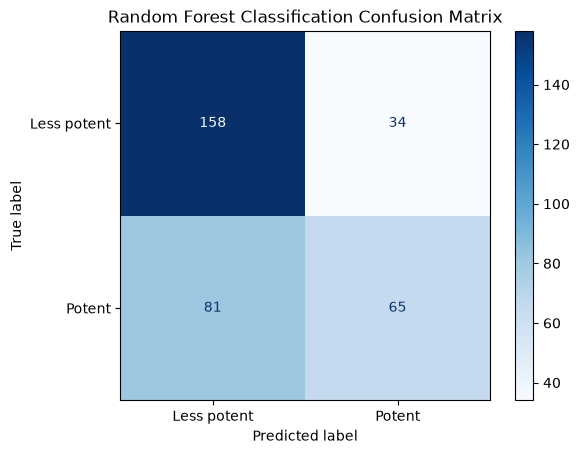

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    y_pred_class,
    display_labels=["Less potent", "Potent"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest Classification Confusion Matrix")
plt.savefig("../results/figures/clf_confusion_matrix_default.png", dpi=200, bbox_inches="tight")
plt.show()

The Random Forest Classifier achieved an accuracy of 65.98%, correctly classifying 223 of 338 test compounds. The confusion matrix showed that 158 less potent and 65 potent compounds were correctly identified. However, 81 potent compounds were incorrectly classified as less potent, resulting in a relatively low recall of 44.52%. This suggests that the model has some ability to distinguish compounds by antiparasitic potency but struggles to identify many genuinely potent candidates.

In [7]:
# Create classifier
rf_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Get out-of-fold probabilities from training data
train_probabilities = cross_val_predict(
    rf_cv,
    X_train_combined,
    y_train_class,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Compare thresholds
results = []

for threshold in np.arange(0.30, 0.71, 0.05):
    predictions = (
        train_probabilities >= threshold
    ).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_train_class, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train_class, predictions
        ),
        "F1": f1_score(
            y_train_class, predictions
        )
    })

threshold_results = pd.DataFrame(results)
threshold_results.round(4).to_csv("../results/tables/classifier_threshold_comparison.csv", index=False)

print(threshold_results.round(4).to_string(index=False))

best_threshold = threshold_results.loc[
    threshold_results["F1"].idxmax(),
    "Threshold"
]

print("\nBest threshold:", best_threshold)

 Threshold  Precision  Recall     F1
      0.30     0.4952  0.8914 0.6367
      0.35     0.5258  0.8086 0.6372
      0.40     0.5671  0.7362 0.6407
      0.45     0.5983  0.6138 0.6060
      0.50     0.6523  0.5207 0.5791
      0.55     0.7088  0.4155 0.5239
      0.60     0.7656  0.3379 0.4689
      0.65     0.8394  0.2793 0.4191
      0.70     0.9000  0.2328 0.3699

Best threshold: 0.4


Random Forest Classification (Threshold = 0.40)
-----------------------------------------------
Accuracy:  0.6509
Precision: 0.5761
Recall:    0.7260
F1-score:  0.6424


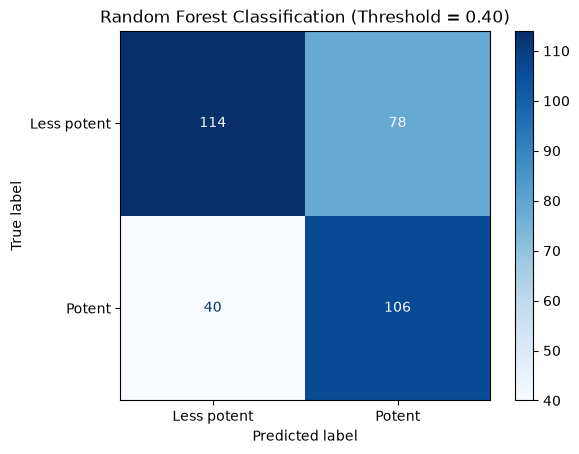

In [8]:
# Predict probabilities using the trained classifier
test_probabilities = rf_classifier.predict_proba(
    X_test_combined
)[:, 1]

# Apply the selected threshold
new_predictions = (
    test_probabilities >= 0.40
).astype(int)

# Evaluate performance
print("Random Forest Classification (Threshold = 0.40)")
print("-----------------------------------------------")
print(f"Accuracy:  {accuracy_score(y_test_class, new_predictions):.4f}")
print(f"Precision: {precision_score(y_test_class, new_predictions):.4f}")
print(f"Recall:    {recall_score(y_test_class, new_predictions):.4f}")
print(f"F1-score:  {f1_score(y_test_class, new_predictions):.4f}")

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    new_predictions,
    display_labels=["Less potent", "Potent"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest Classification (Threshold = 0.40)")
plt.savefig("../results/figures/clf_confusion_matrix_tuned.png", dpi=200, bbox_inches="tight")
plt.show()

### Classification Results and Conclusion

A Random Forest Classifier was developed to classify compounds as potent (pEC50 ≥ 6) or less potent (pEC50 < 6) using molecular descriptors and Morgan fingerprints.

Using the default classification threshold of 0.50, the model achieved 65.98% accuracy, 44.52% recall and an F1-score of 0.5306.

To improve the identification of potent compounds, different classification thresholds were evaluated using five-fold cross-validation on the training dataset. A threshold of 0.40 was selected based on the highest F1-score.

Applying this threshold to the test dataset increased recall to 72.60% and the F1-score to 0.6424, while accuracy decreased slightly to 65.09%. The number of correctly identified potent compounds increased from 65 to 106.

These findings demonstrate that adjusting the classification threshold can improve the identification of potentially active antiparasitic compounds, although this comes at the cost of more false positives. Overall, the classifier shows moderate predictive ability but would require further improvement before being used for reliable compound screening.